In [1]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester

In [2]:
# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Bars: 23,033
Date range: 2026-02-01 23:00:07.009440-06:00 to 2026-03-02 07:28:53.006560-06:00


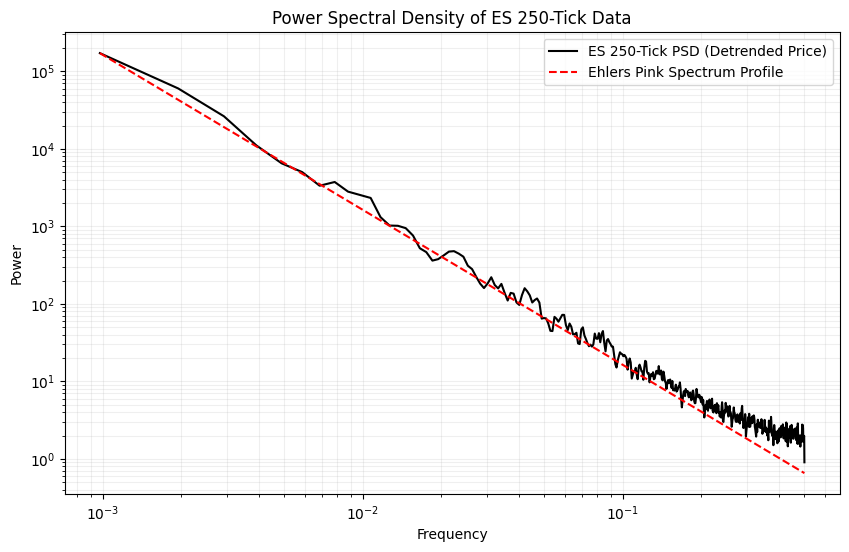

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, detrend

# 1. Use the RAW close prices, but linearly detrend them to remove the macro slope
# This satisfies the FFT's need for a zero-mean without destroying the $1/f$ amplitude
stationary_close = detrend(close, type='linear')

# 2. Compute Power Spectral Density using Welch's method
frequencies, psd = welch(stationary_close, nperseg=1024)

# 3. Drop the DC component (0 frequency) for log-log plotting
frequencies = frequencies[1:]
psd = psd[1:]

plt.figure(figsize=(10, 6))
# Plot the actual market PSD on a log-log scale
plt.loglog(frequencies, psd, label='ES 250-Tick PSD (Detrended Price)', color='black')

# Plot a reference line for pure Pink Noise
# Note: Ehlers' 6dB/octave amplitude drop means Power drops at 12dB/octave (1/f^2)
pink_reference = psd[0] * ((frequencies[0] / frequencies) ** 2)
plt.loglog(frequencies, pink_reference, label='Ehlers Pink Spectrum Profile', color='red', linestyle='--')

plt.title('Power Spectral Density of ES 250-Tick Data')
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.show()

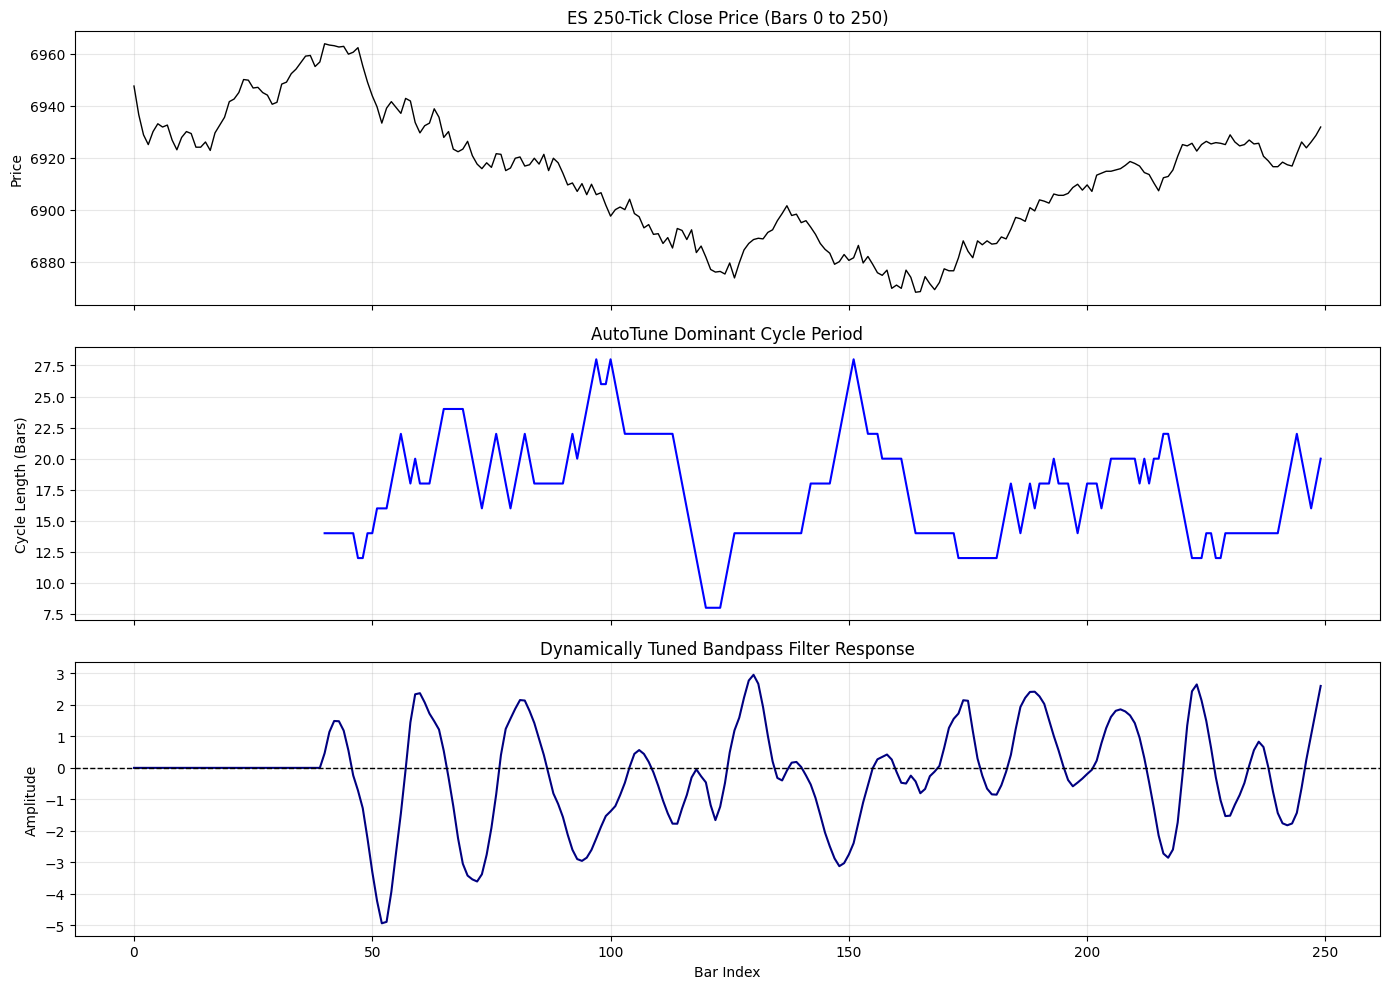

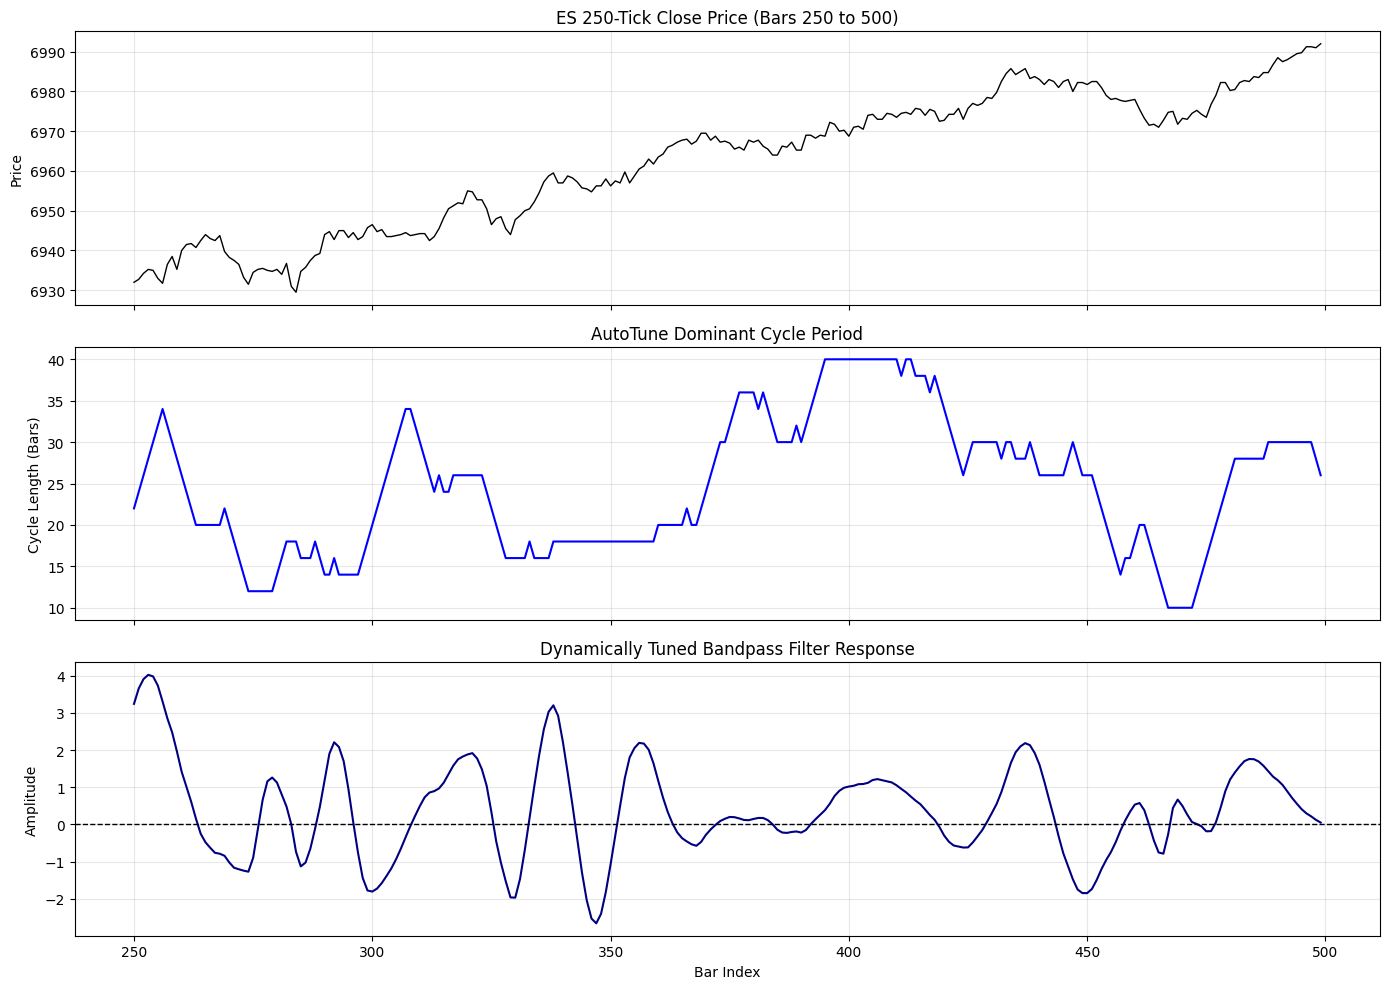

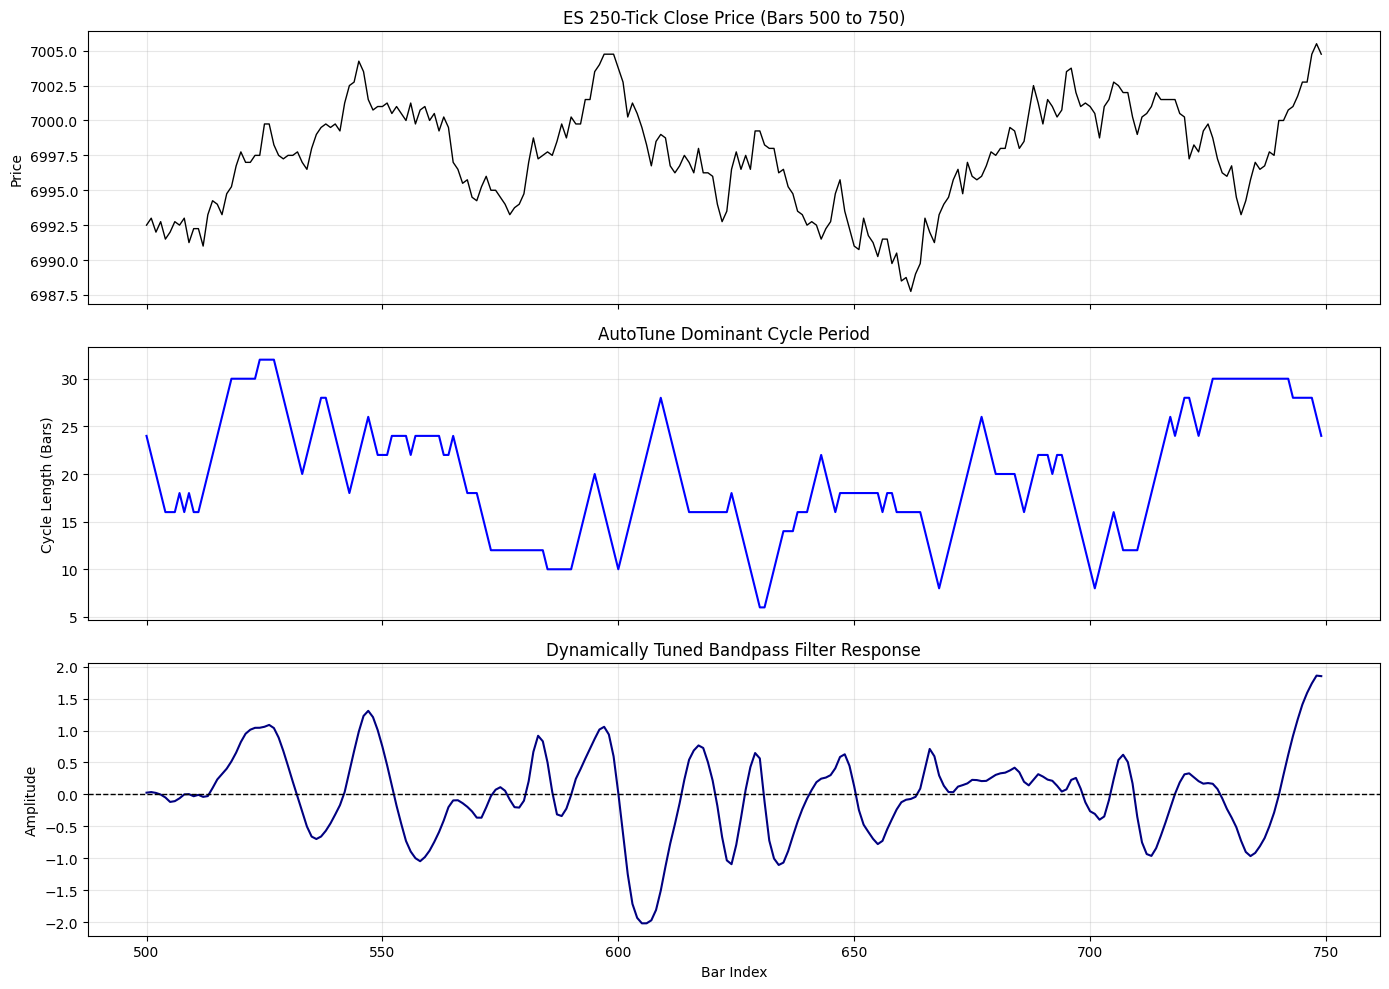

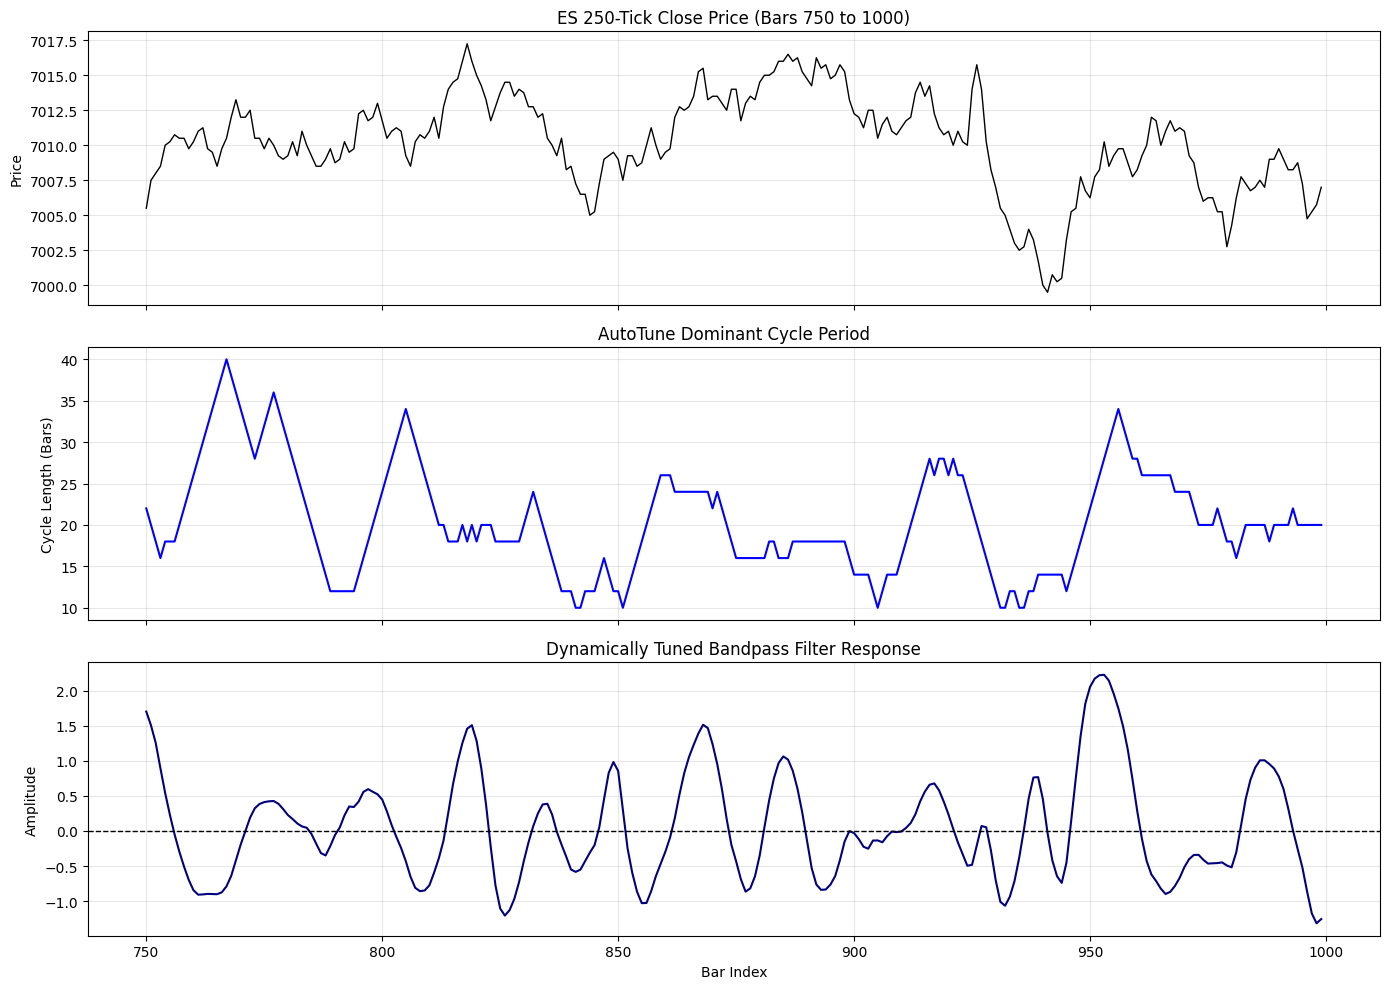

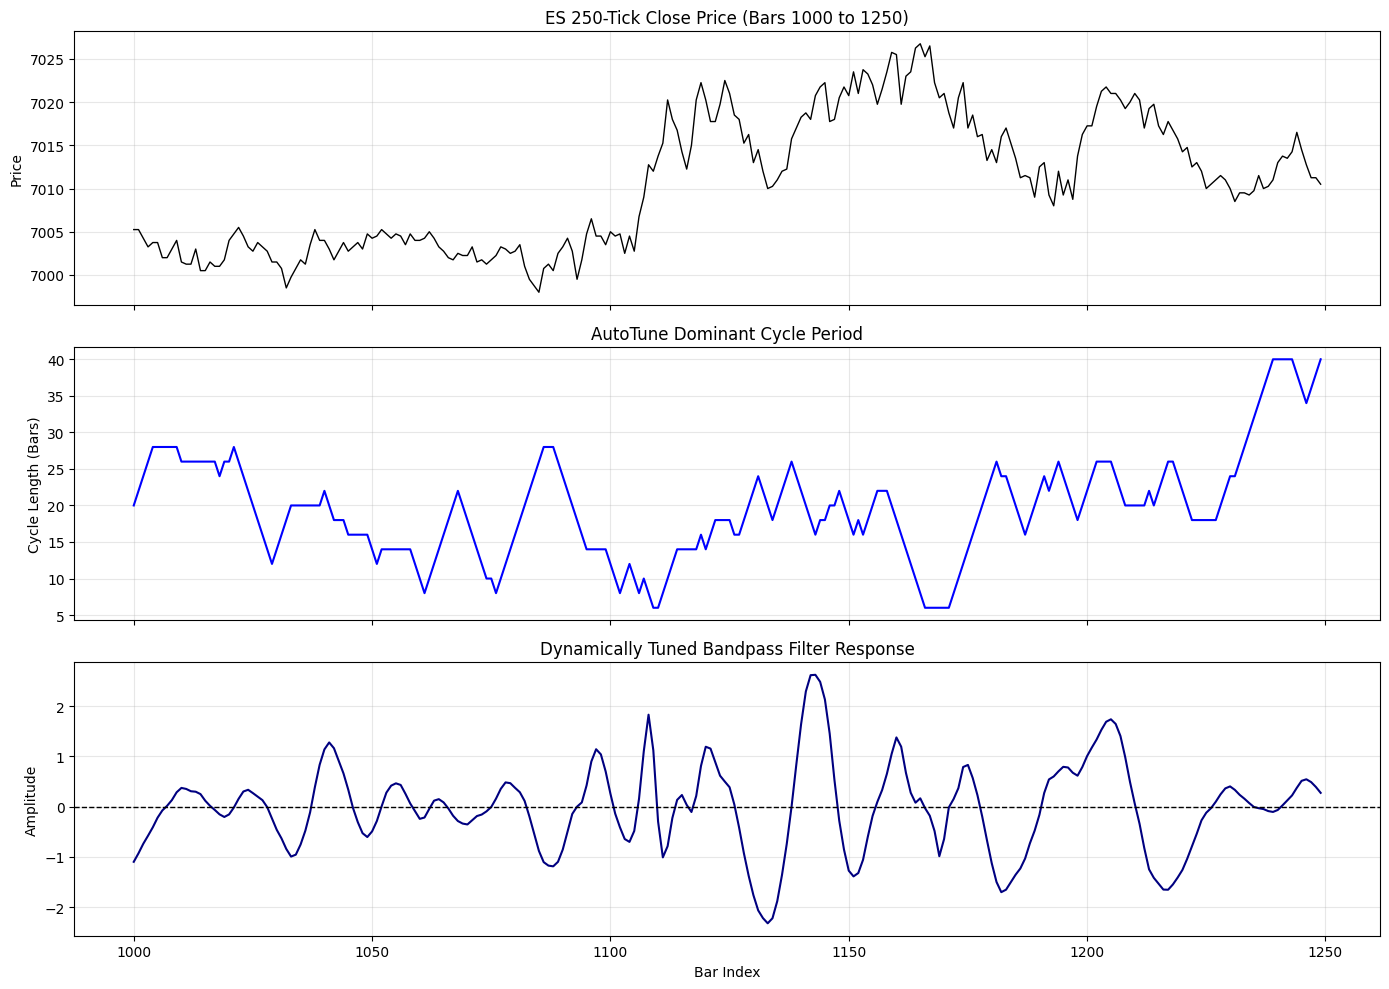

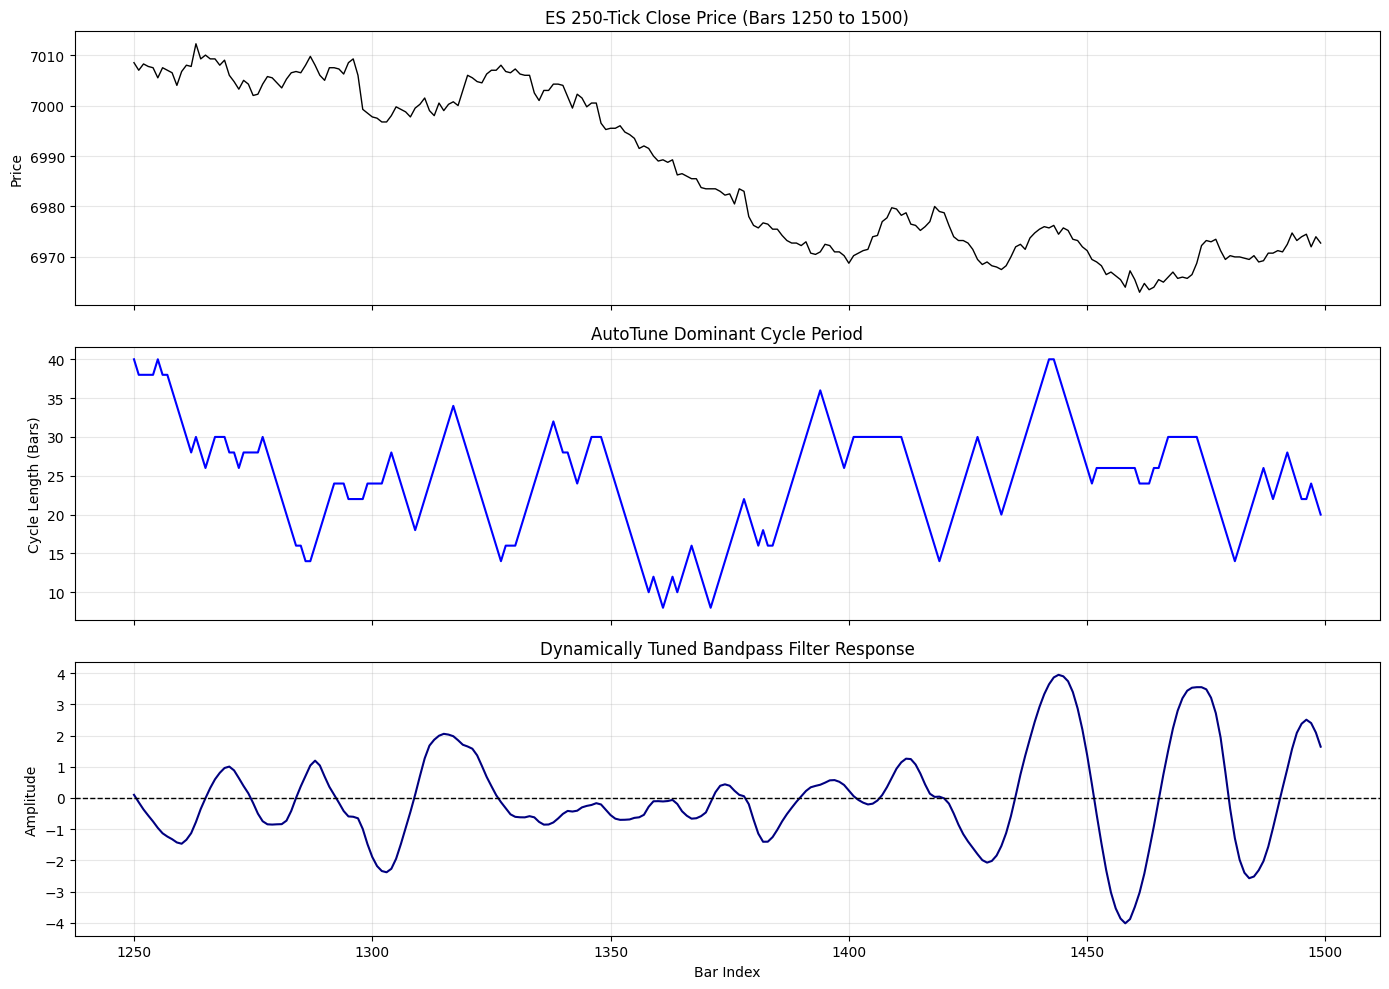

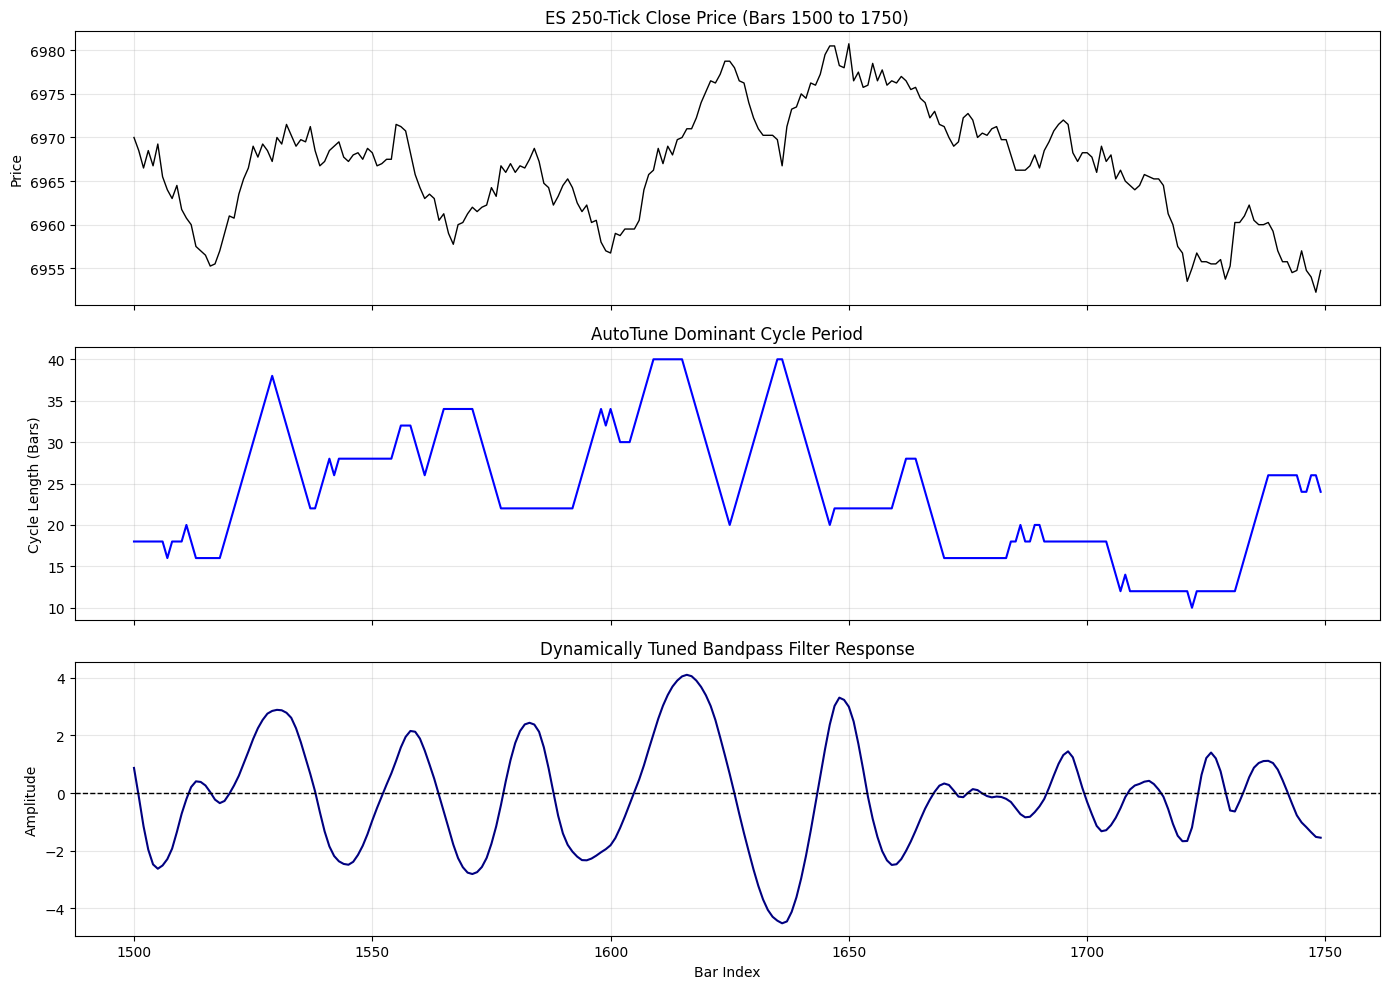

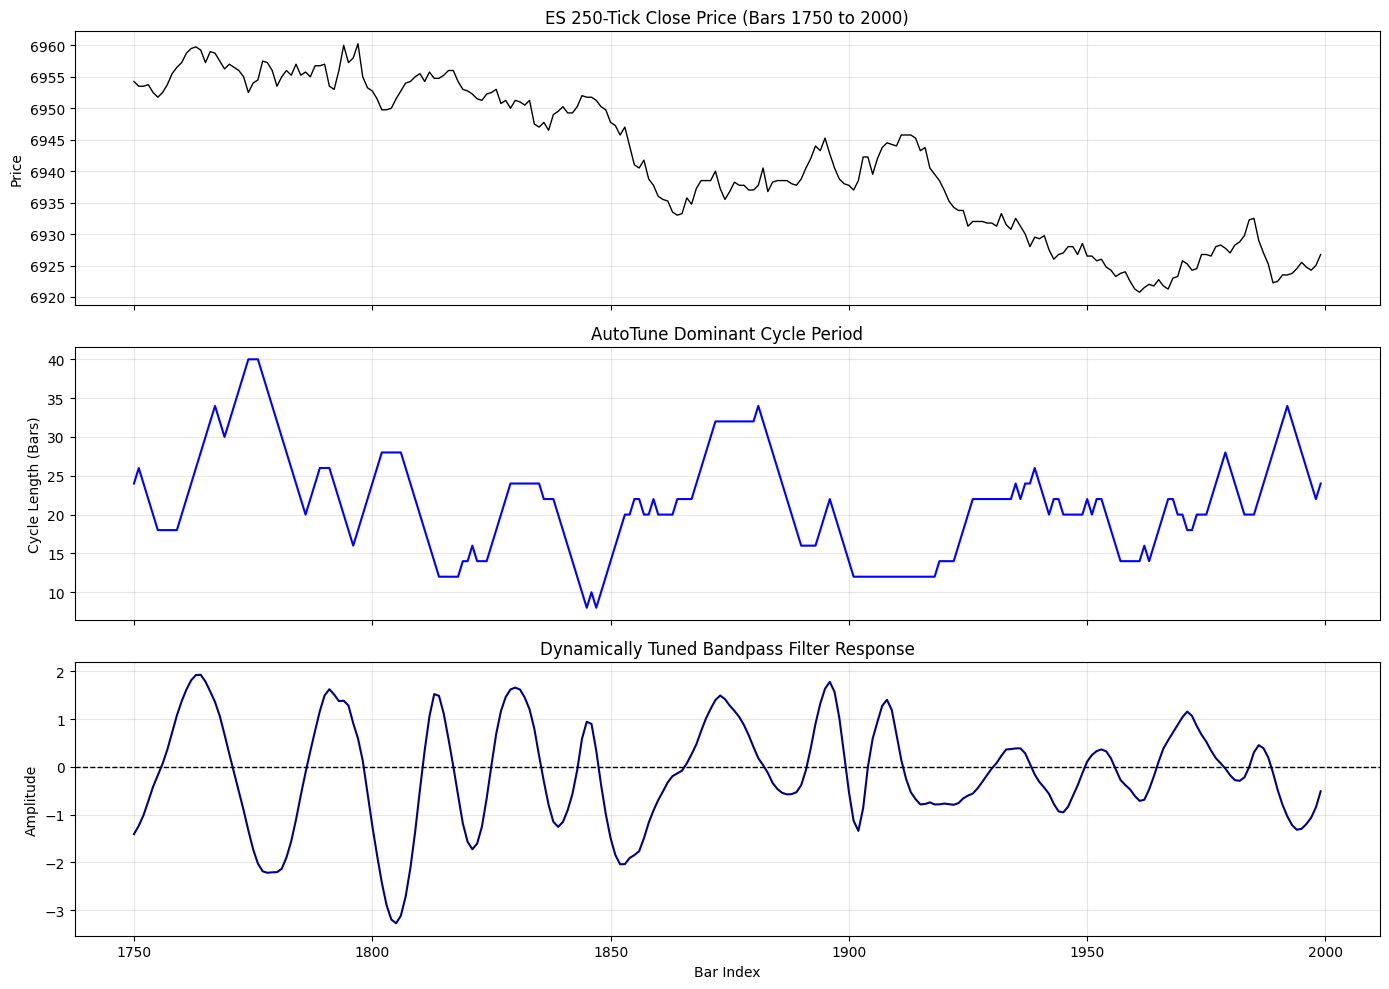

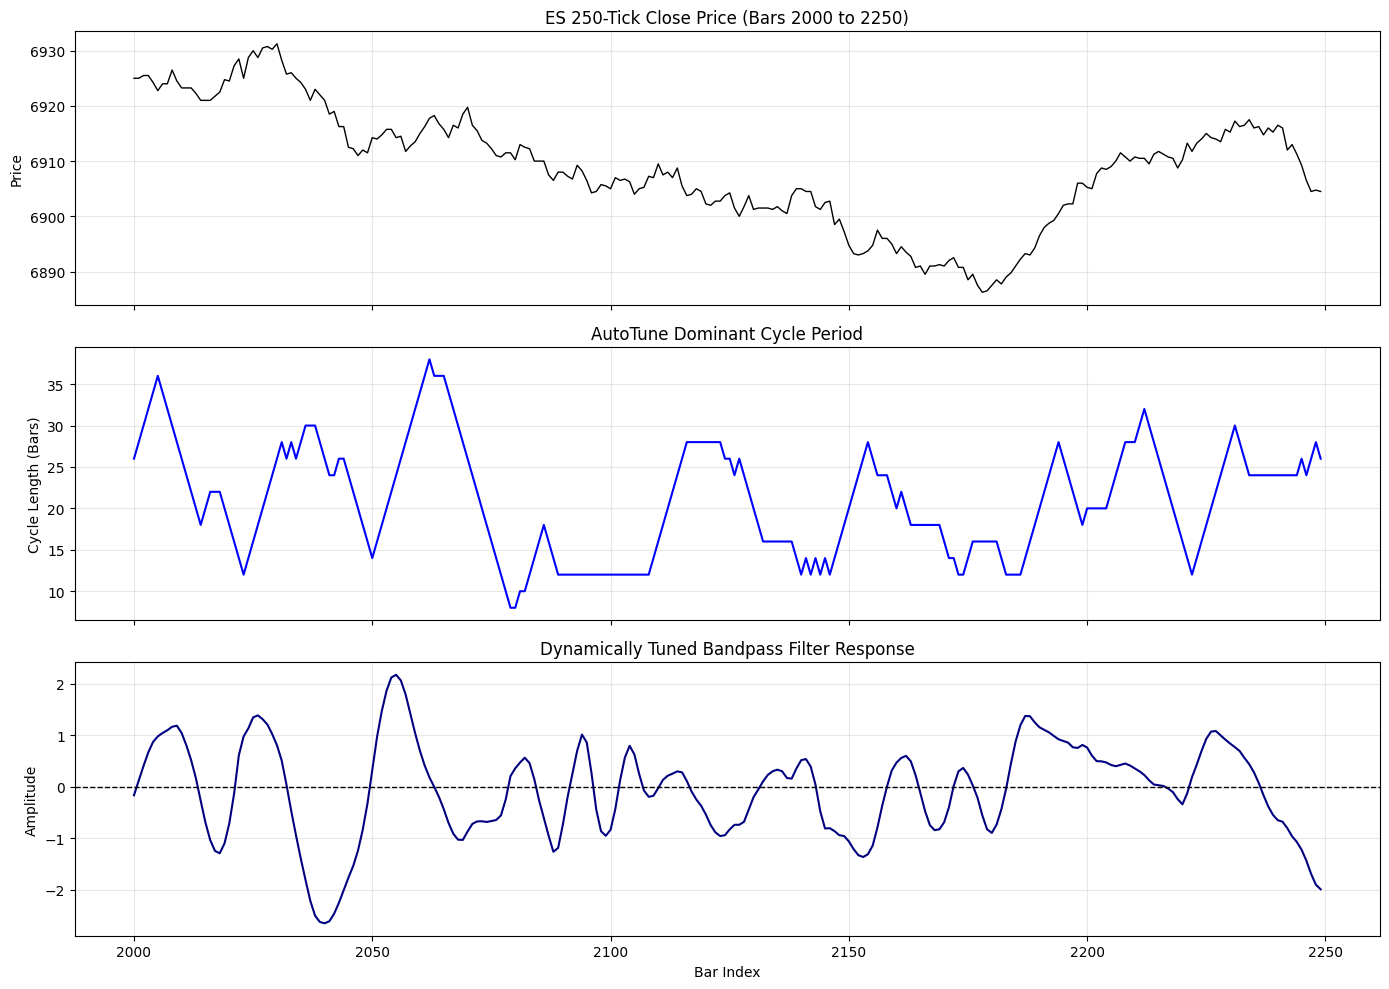

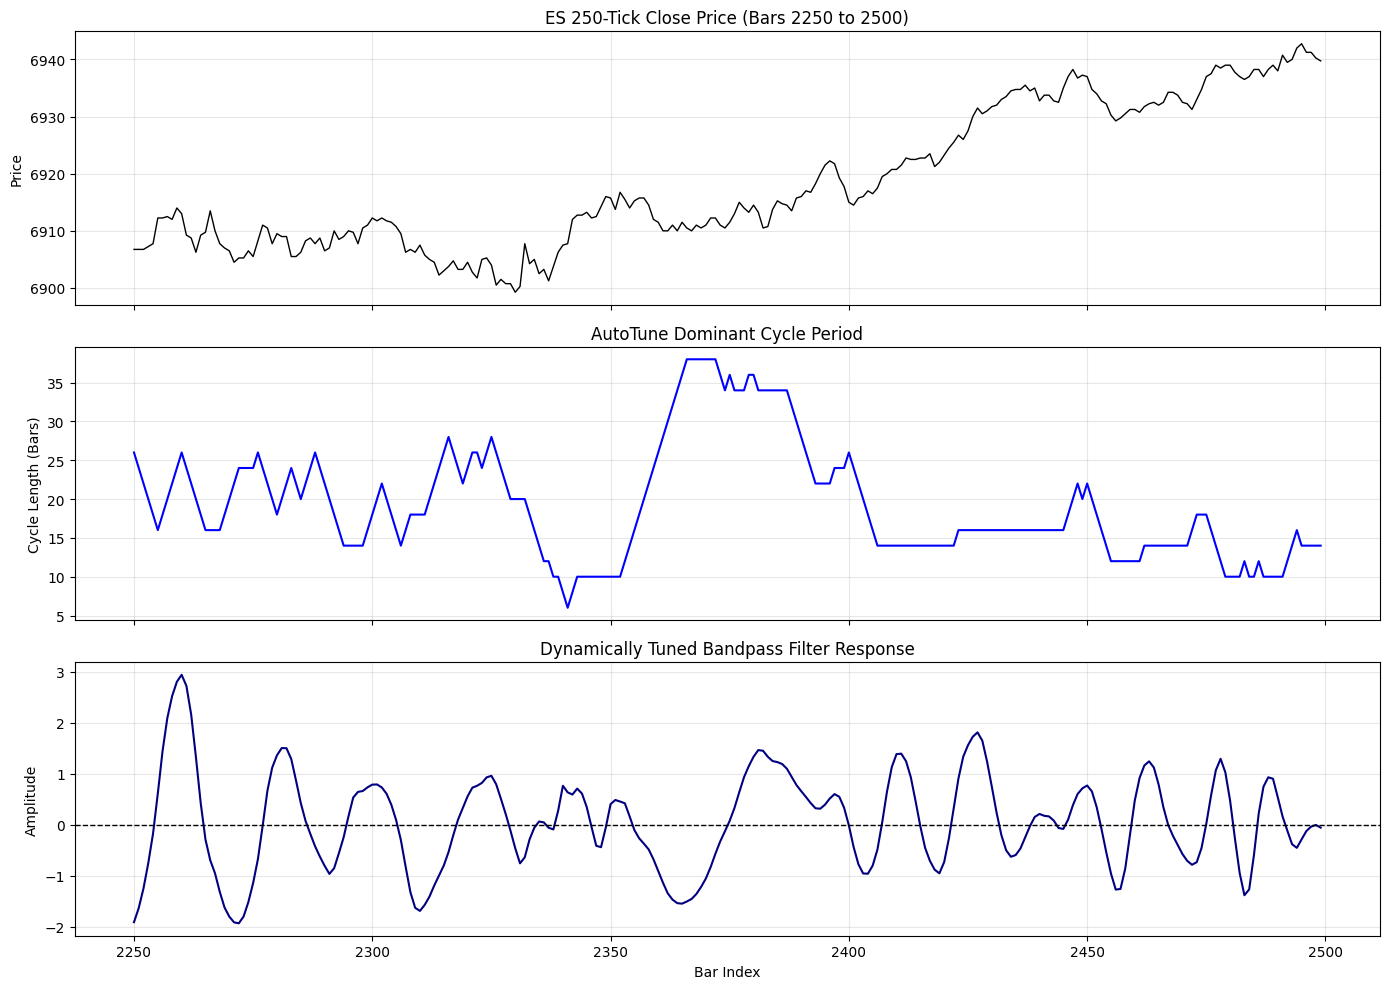

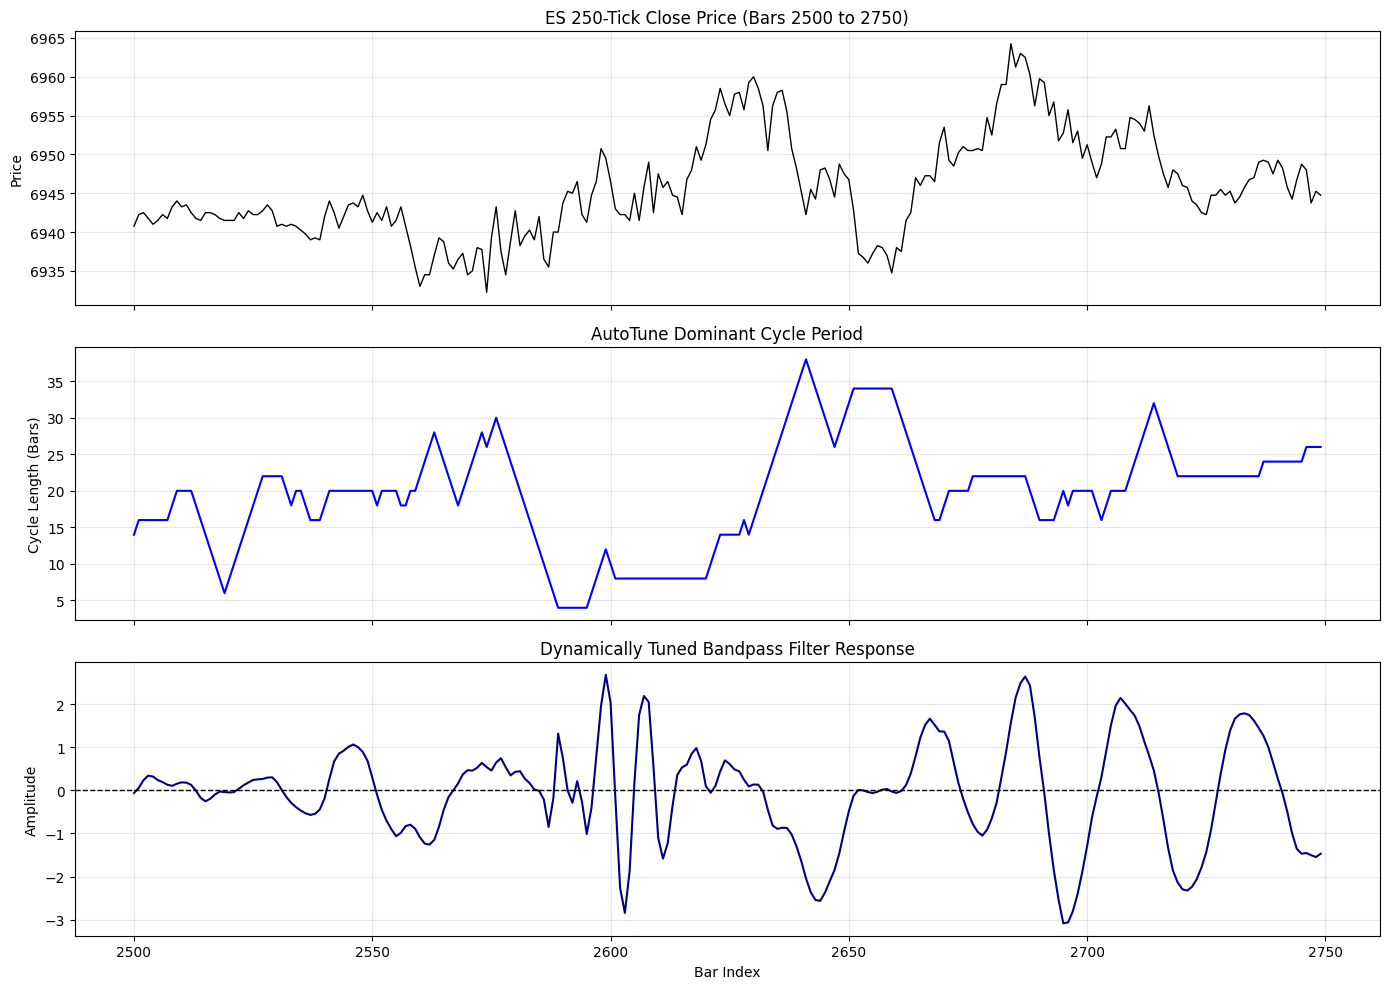

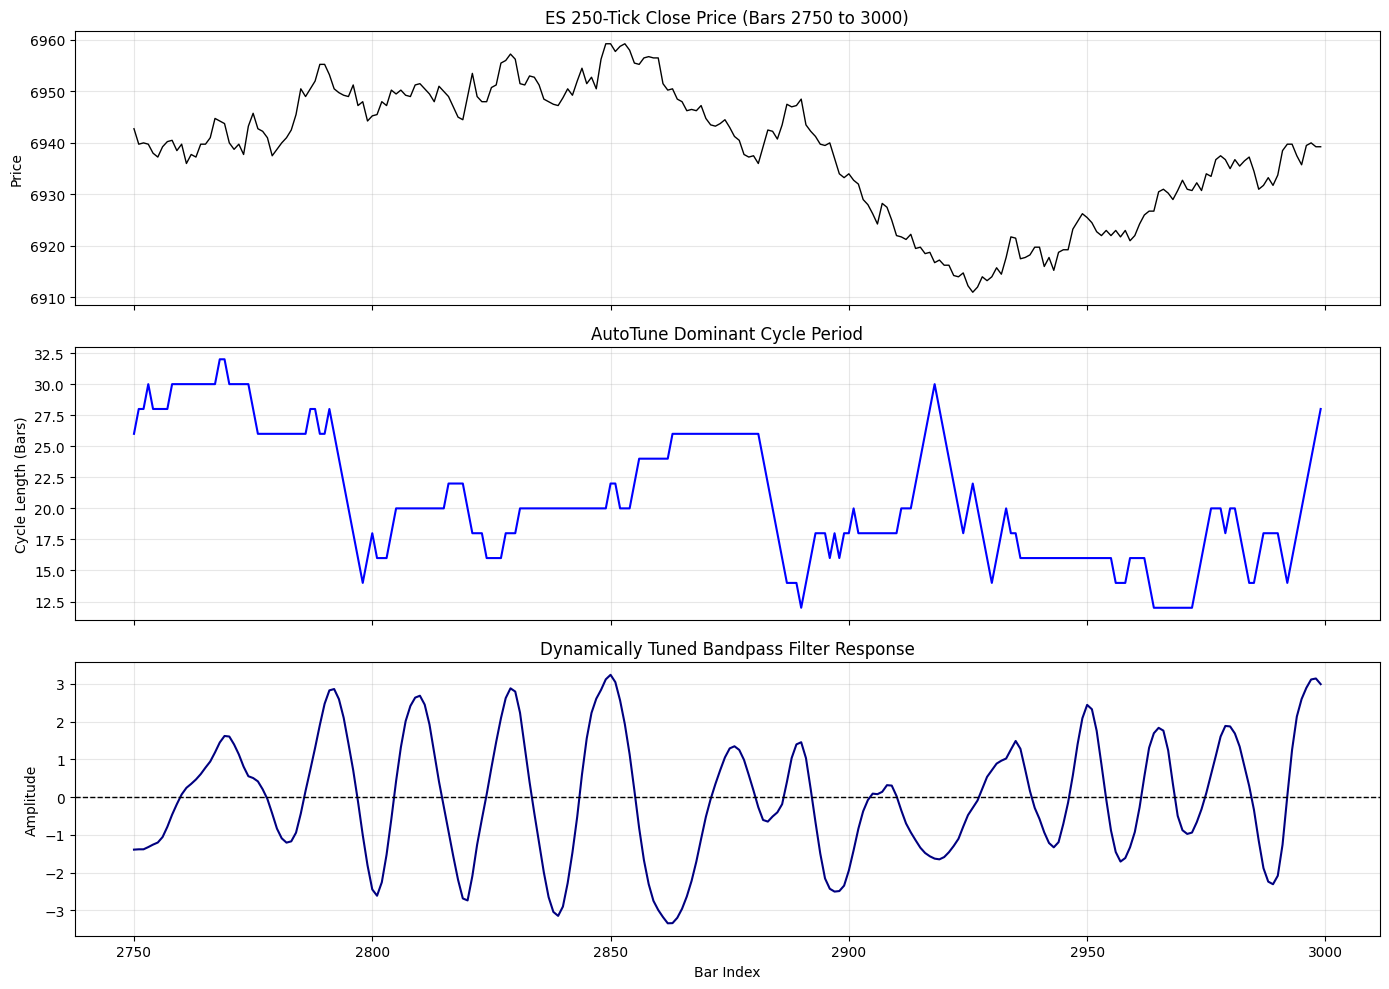

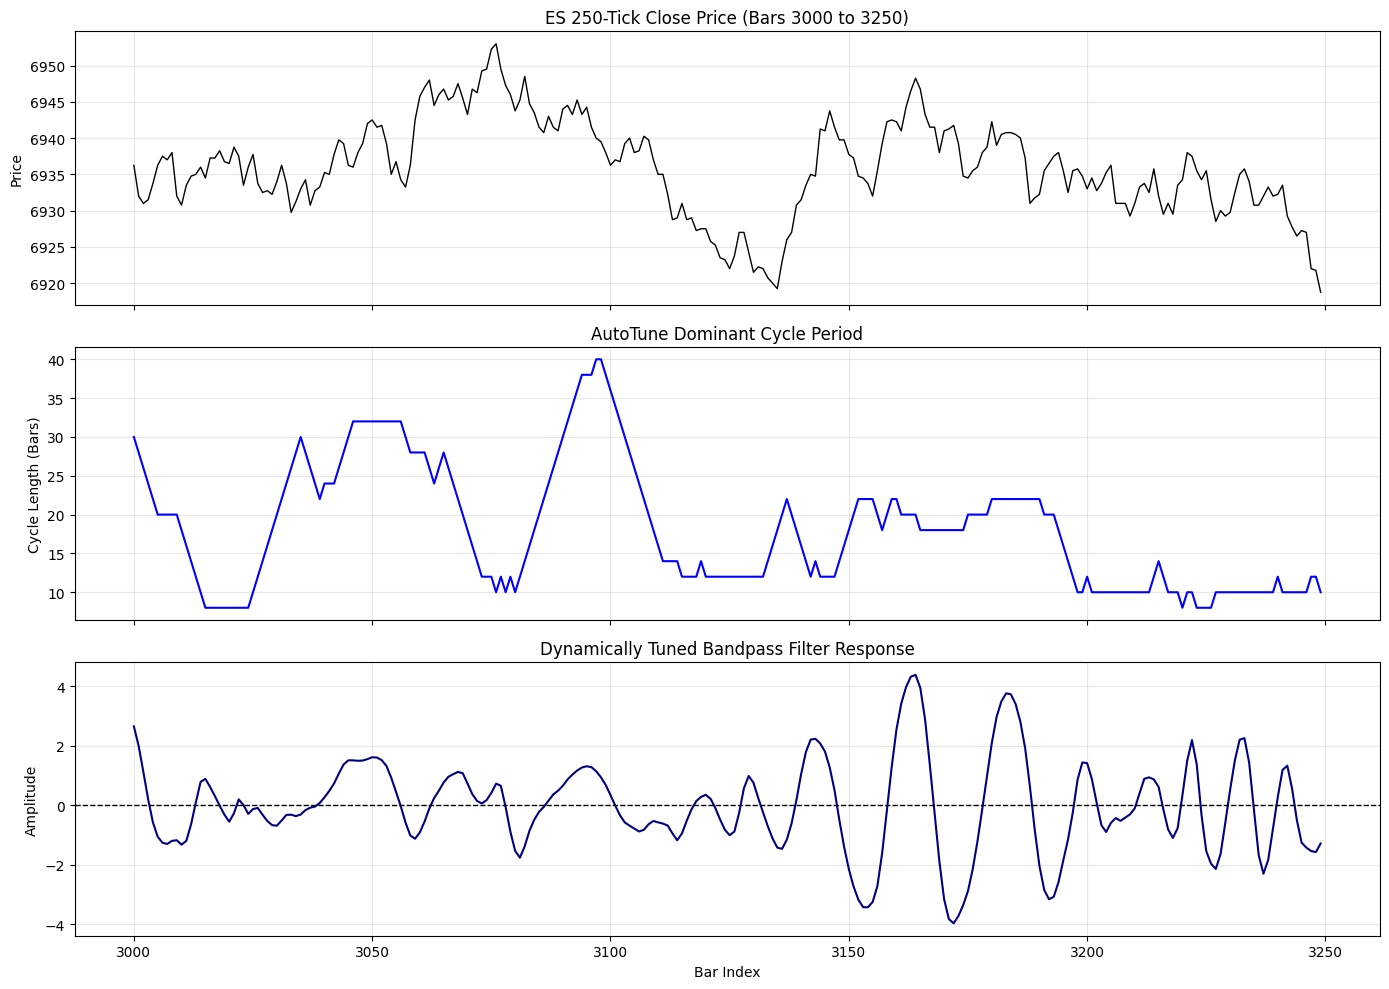

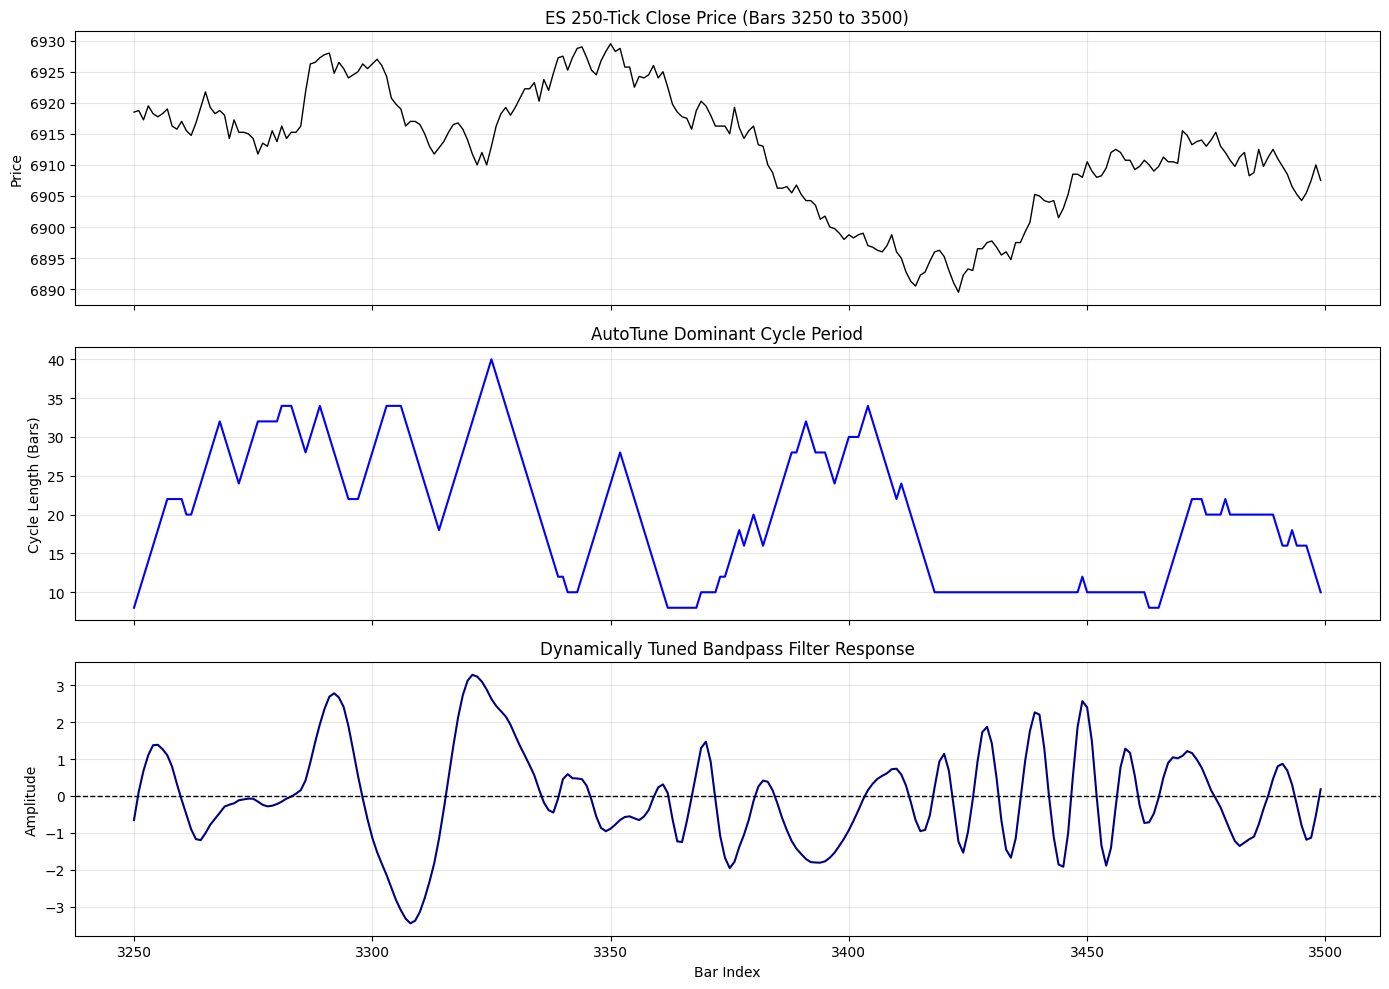

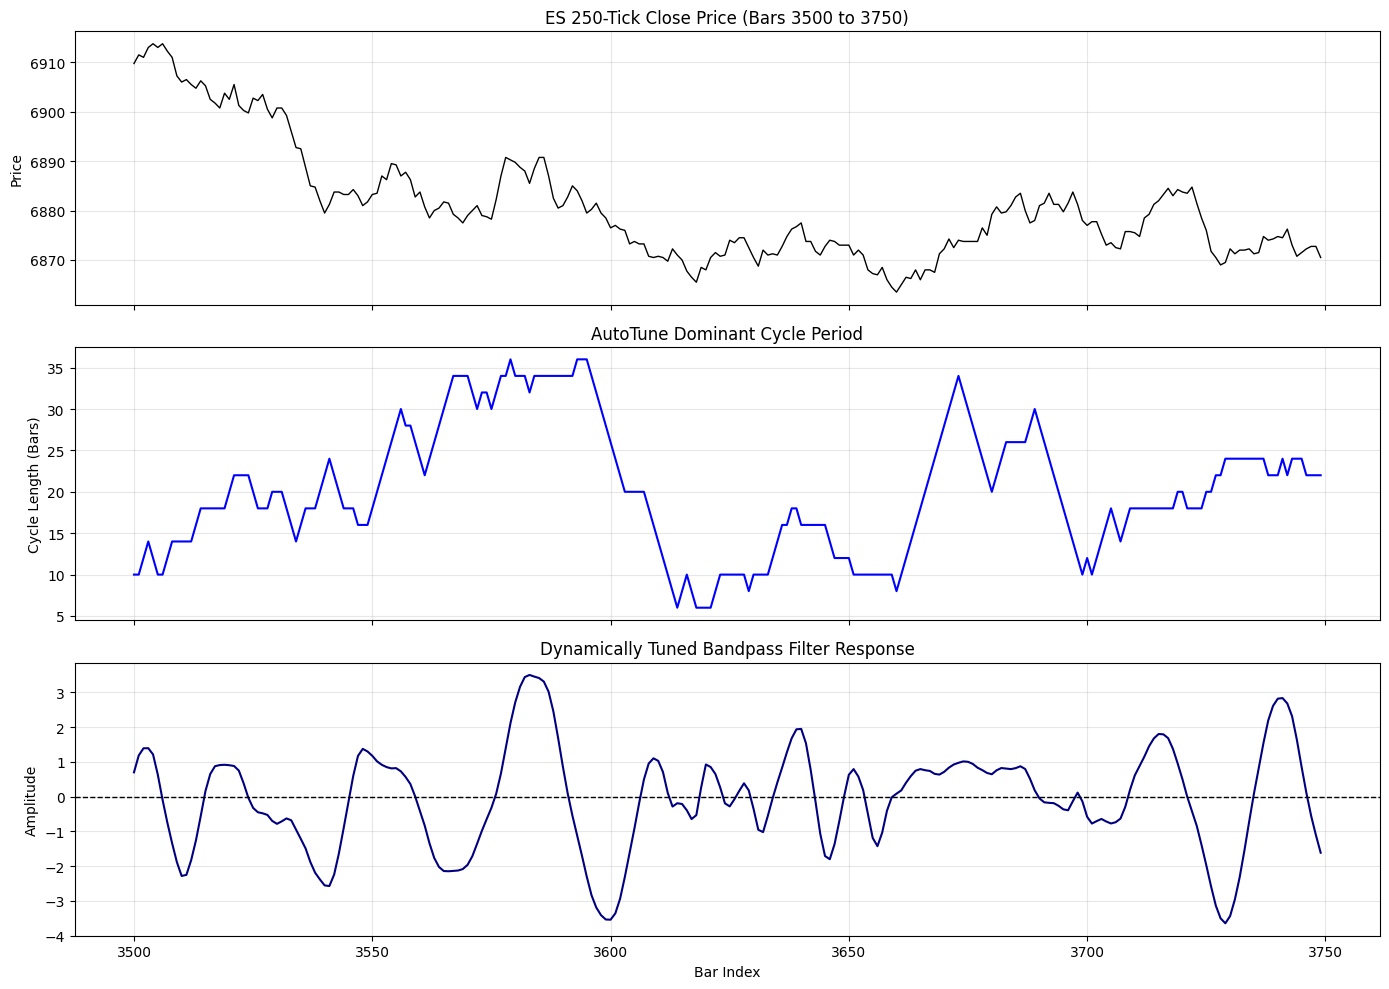

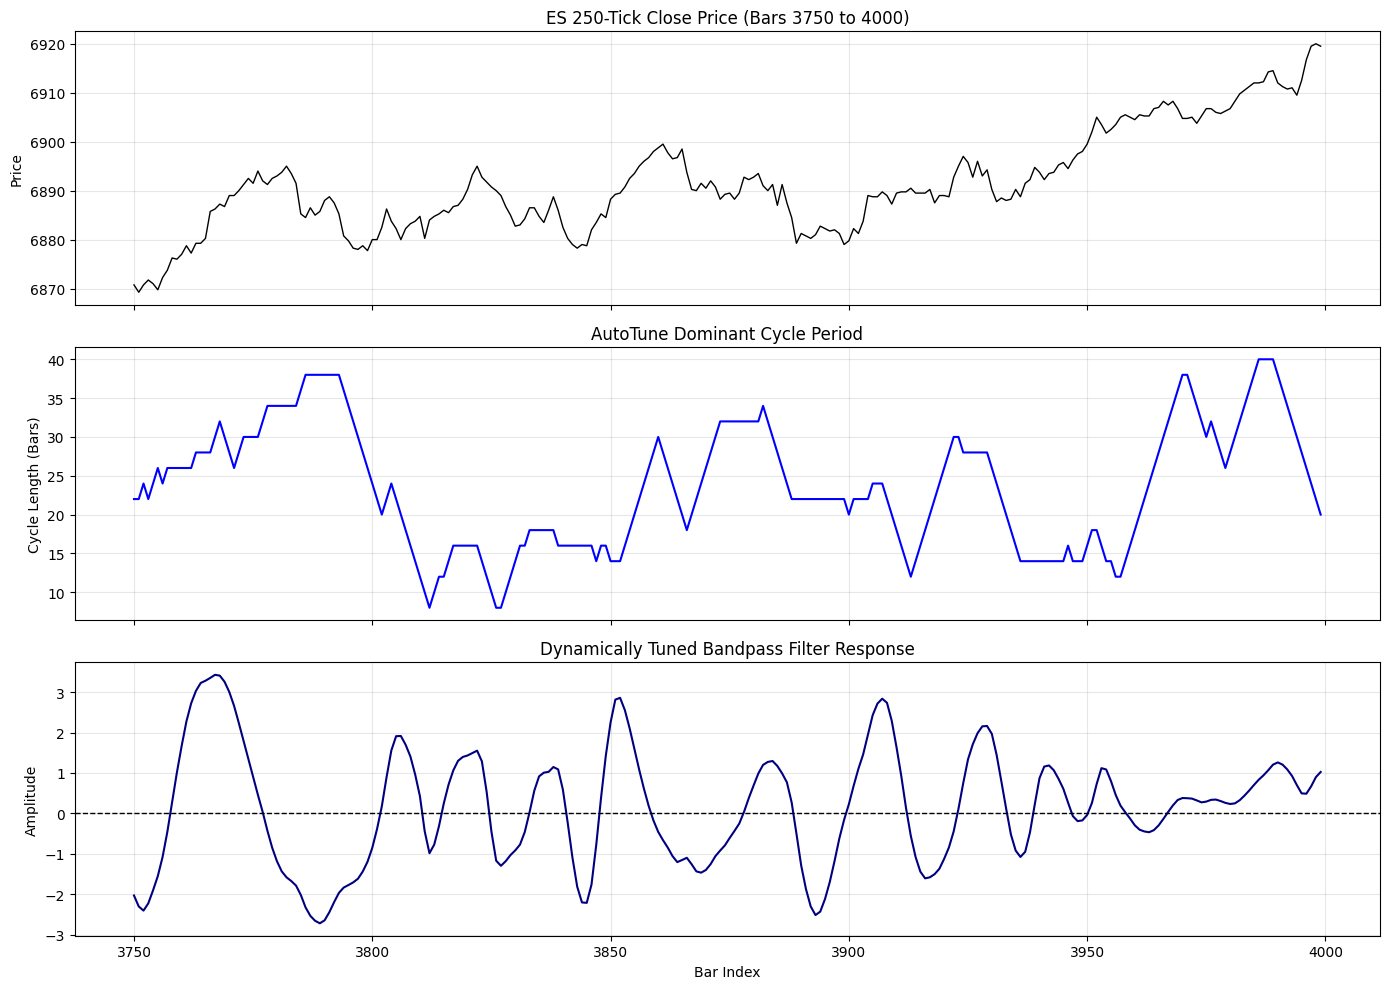

KeyboardInterrupt: 

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Data Loading 
# ==============================================================================
# Load ES tick data and aggregate into 250-tick bars
# td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
# td.aggregate(method='tick', size=250)
# close = td.get_ohlc()[:, 3]


# ==============================================================================
# 2. Ehlers Highpass Filter Function (Code Listing 3)
# ==============================================================================
def ehlers_highpass(price, period):
    n = len(price)
    hp = np.zeros(n)
    
    # 1.414 is approx sqrt(2). 180 degrees is pi.
    q = np.exp(-np.sqrt(2) * np.pi / period)
    c1 = 2 * q * np.cos(np.sqrt(2) * np.pi / period)
    c2 = q * q
    a0 = (1 + c1 + c2) / 4.0
    
    for i in range(2, n):
        hp[i] = a0 * (price[i] - 2*price[i-1] + price[i-2]) + c1 * hp[i-1] - c2 * hp[i-2]
        
    return hp

# ==============================================================================
# 3. AutoTune Dominant Cycle & Correlation Engine (Code Listing 1)
# ==============================================================================
window = 20

# 1. Filter the data to get a nominally zero mean
filt = ehlers_highpass(close, window)
s_filt = pd.Series(filt)

dom_cycle = np.zeros(n_bars)
min_corr_array = np.zeros(n_bars)

# Precalculate the rolling correlation matrix for lags 1 through Window
corr_matrix = np.zeros((window + 1, n_bars))
for lag in range(1, window + 1):
    s_shifted = s_filt.shift(lag)
    # Using Pandas rolling correlation to match Ehlers' summation math exactly
    corr_matrix[lag, :] = s_filt.rolling(window=window).corr(s_shifted).fillna(0).values

dc_prev = 0

for i in range(window * 2, n_bars):
    # Extract correlations for the current bar
    corrs = corr_matrix[1:window + 1, i]
    
    # Find minimum correlation and Dominant Cycle
    min_idx = np.argmin(corrs)
    min_corr = corrs[min_idx]
    best_lag = min_idx + 1  # Offset by 1 because range started at 1
    
    dc = 2 * best_lag
    
    # Ehlers' Rate of Change Limiter (Stops the cycle from jumping erratically)
    if dc_prev != 0:
        if dc > dc_prev + 2:
            dc = dc_prev + 2
        if dc < dc_prev - 2:
            dc = dc_prev - 2
            
    dom_cycle[i] = dc
    min_corr_array[i] = min_corr
    dc_prev = dc

# ==============================================================================
# 4. Dynamic Bandpass Filter Tuned Bar-By-Bar (Code Listing 4 & 1)
# ==============================================================================
bp = np.zeros(n_bars)
# Ehlers arbitrarily sets the bandwidth to a percentage of the tuned center.
# In Listing 1 he used 25, in Listing 2 he used 0.22. We use 0.25 (25%).
bandwidth = 0.25 

for i in range(2, n_bars):
    period = dom_cycle[i]
    if period == 0:
        continue
        
    l1 = np.cos(2 * np.pi / period)
    g1 = np.cos(bandwidth * 2 * np.pi / period)
    
    # Protect against division by zero in the square root
    if g1 != 0 and (1.0 / (g1 * g1) - 1.0) >= 0:
        s1 = 1.0 / g1 - np.sqrt(1.0 / (g1 * g1) - 1.0)
        # Bandpass equation
        bp[i] = 0.5 * (1.0 - s1) * (close[i] - close[i-2]) + l1 * (1.0 + s1) * bp[i-1] - s1 * bp[i-2]

# ==============================================================================
# 5. Plotting in 1000-Bar Intervals
# ==============================================================================
chunk_size = 250
num_chunks = int(np.ceil(n_bars / chunk_size))
t_array = np.arange(n_bars)

for i in range(num_chunks):
    start_idx = i * chunk_size
    end_idx = min(start_idx + chunk_size, n_bars)
    
    t_chunk = t_array[start_idx:end_idx]
    price_chunk = close[start_idx:end_idx]
    dc_chunk = dom_cycle[start_idx:end_idx]
    bp_chunk = bp[start_idx:end_idx]
    
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    
    # Subplot 1: Price
    ax1.plot(t_chunk, price_chunk, color='black', linewidth=1)
    ax1.set_title(f'ES 250-Tick Close Price (Bars {start_idx} to {end_idx})')
    ax1.set_ylabel('Price')
    ax1.grid(True, alpha=0.3)
    
    # Subplot 2: Dominant Cycle Period (Matches Figure 3 in PDF)
    # Filter out 0s at the start so the line doesn't drop to the floor
    dc_plot = np.where(dc_chunk > 0, dc_chunk, np.nan)
    ax2.plot(t_chunk, dc_plot, color='blue', linewidth=1.5)
    ax2.set_title('AutoTune Dominant Cycle Period')
    ax2.set_ylabel('Cycle Length (Bars)')
    ax2.grid(True, alpha=0.3)
    
    # Subplot 3: AutoTuned Bandpass Filter (Matches Figure 4 in PDF)
    ax3.plot(t_chunk, bp_chunk, color='navy', linewidth=1.5)
    ax3.axhline(0, color='black', linewidth=1, linestyle='--')
    ax3.set_title('Dynamically Tuned Bandpass Filter Response')
    ax3.set_ylabel('Amplitude')
    ax3.set_xlabel('Bar Index')
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [5]:
def ultimate_smoother(price: np.ndarray, period: float) -> np.ndarray:
    """Ehlers Ultimate Smoother - zero lag in pass band."""
    n = len(price)
    us = np.copy(price).astype(float)

    a1 = np.exp(-1.414 * np.pi / period)
    b1 = 2 * a1 * np.cos(1.414 * np.pi / period)
    c2 = b1
    c3 = -a1 * a1
    c1 = (1 + c2 - c3) / 4

    for i in range(3, n):
        us[i] = ((1 - c1) * price[i]
                 + (2 * c1 - c2) * price[i - 1]
                 - (c1 + c3) * price[i - 2]
                 + c2 * us[i - 1]
                 + c3 * us[i - 2])

    return us

In [ ]:
# Sweep cutoff periods to find optimal edge
periods = np.arange(5, 101, 5)
results = []

for p in periods:
    us_p = ultimate_smoother(close, p)
    slope_p = np.diff(us_p, prepend=us_p[0])
    inc_p = slope_p[:-1] > 0
    out = next_close_above[:-1]

    p_inc = out[inc_p].mean() if inc_p.sum() > 0 else 0.5
    p_dec = out[~inc_p].mean() if (~inc_p).sum() > 0 else 0.5

    results.append({
        'period': p,
        'p_above_inc': p_inc,
        'p_above_dec': p_dec,
        'edge_inc': p_inc - 0.5,
        'edge_dec': 0.5 - p_dec,
        'total_edge': (p_inc - p_dec),
        'n_inc': inc_p.sum(),
        'n_dec': (~inc_p).sum(),
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))
print(f'\nBest total edge at period = {df_results.loc[df_results["total_edge"].idxmax(), "period"]}')

NameError: name 'next_close_above' is not defined

In [18]:
# === STRATEGY: always long when US increasing, always short when decreasing ===

CUTOFF_PERIOD = 20  # <-- CHANGE THIS to adjust cutoff frequency

us_strat = ultimate_smoother(close, CUTOFF_PERIOD)
us_slope_strat = np.diff(us_strat, prepend=us_strat[0])

signal = np.zeros(n_bars)
for i in range(3, n_bars):
    if us_slope_strat[i] > 0 and close[i] > us_strat[i]:
        signal[i] = 1
    elif us_slope_strat[i] < 0 and close[i] < us_strat[i]:
        signal[i] = -1

n_flips = int(np.sum(np.abs(np.diff(signal)) > 0))
n_long = int(np.sum(signal == 1))
n_short = int(np.sum(signal == -1))
print(f'Cutoff Period: {CUTOFF_PERIOD}')
print(f'Position flips: {n_flips:,}')
print(f'Bars long: {n_long:,} | Bars short: {n_short:,} | Bars flat: {int(np.sum(signal == 0)):,}')

Cutoff Period: 20
Position flips: 9,568
Bars long: 8,116 | Bars short: 8,347 | Bars flat: 6,570


In [19]:
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=1.0,
    commission=3.5,
)
bt.full_backtest()
print(bt)


        Backtest Results from 2026-02-01 23:00:07.009440-06:00 to 2026-03-02 07:28:53.006560-06:00 (28 days 08:28:45.997120)
        Equity:     $100,000.00 -> $10,868.50
        Buy & Hold: $100,000.00 -> $92,375.00
        Buy & Hold Return (%): -7.62%
        Strategy Return (%):   -89.13%

        Total Trades:     5309.00
        Win Rate:         32.12%
        95% CI:           30.87% - 33.38%
        Avg. Win:         $154.84
        Avg. Loss:        $-97.99
        Ratio Win/Loss:   1.58
        Expected Value:   $-16.79

        Largest Win:      $1,334.00
        Largest Loss:     $-1,278.50
        Max Consec. Wins: 7
        Max Consec. Loss: 18

        Max Drawdown from 2026-02-02 01:14:01.007960-06:00 to 2026-03-02 07:28:53.006560-06:00 (28 days 06:14:51.998600)
        Max Drawdown:     $-89,996.50
        Max Drawdown (%): -89.22%

        Slippage:   1.0 ticks
        Commission: $3.50
        Contract Multiplier: $50.00
        Transaction Costs:   $84,944.00

   

In [20]:
from Engine.Report import generate_report
generate_report(bt, 'backtest_report.html', open_browser=True)

Report saved: /Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html


'/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html'